# M3AE 베이스라인 재현 — VQA-RAD + SLAKE

논문: *Multi-Modal Masked Autoencoders for Medical Vision-and-Language Pre-Training*
(arXiv:2209.07098, MICCAI 2022) — CLIP-ViT-B 비전 인코더 + RoBERTa-base 텍스트 인코더, 분류형(classification) MedVQA.

**재현 목표 (Expert-CFG 논문 Table 1 기준)**

| 데이터셋 | Open | Closed | Overall |
|---|---|---|---|
| VQA-RAD | 67.23 | 83.46 | 77.01 |
| SLAKE   | 80.31 | 87.82 | 83.14 |

Repo: https://github.com/zhjohnchan/M3AE (PyTorch Lightning 1.3, `main.py` + sacred named config)

## 구성
| 절 | 내용 |
|---|---|
| 0. 환경 준비 | repo clone, Drive, **Python 3.8 venv** (repo 는 torch 1.9 / PL 1.3.2 / numpy 1.19 고정) |
| 1. 사전학습 체크포인트 | `m3ae.ckpt` |
| 2. 데이터 — VQA-RAD | `data/finetune_data/vqa_rad/{train,val,test}set.json` + `images/` |
| 3. 데이터 — SLAKE | `data/finetune_data/slack/{train,validate,test}.json` + `imgs/` (HF `BoKelvin/SLAKE` 원본 파일) |
| 4. arrow 전처리 | `prepro_vqa_vqa_rad()`, `prepro_vqa_slack()` 만 호출 |
| 5. 학습+테스트 — VQA-RAD | `run_scripts/finetune_m3ae.sh` 와 같은 인자 |
| 6. 학습+테스트 — SLAKE | 같음 + `clip_resizedcrop` |
| 7. 결과 요약 | 로그에서 점수 추출 |

**코드를 읽고 확인한 사항 (실행해 본 것은 아님)**
- 데이터 경로는 `prepro_finetuning_data.py` 안에 `data/finetune_data/...`, `data/finetune_arrows/` 상대 경로로 하드코딩돼 있어서 **cwd 가 `/content/M3AE` 여야** 합니다.
- 스크립트의 `__main__` 은 MedVQA-2019, MELINDA, ROCO 까지 전부 실행해서 데이터가 없으면 죽습니다 → 필요한 함수 두 개만 호출합니다.
- 공식 `finetune_m3ae.sh` 는 `data_root=data/finetune_arrows/ image_size=384` 를 쓰고 SLAKE 는 `clip_resizedcrop` 을 추가합니다 (`config.py` 기본 576 은 쓰지 않음).
- `main.py` 는 `exp_name` 에 `finetune` 이 들어 있을 때만 `fit` 후 `trainer.test(ckpt_path="best")` 를 자동 실행합니다(그래서 실험 이름에 `finetune` 을 유지). best 는 **val** 점수(`val/the_metric`) 기준이라 test 로 고르지 않습니다.
- 답 어휘(label set)는 레포 원본에서는 `make_arrow_vqa` 가 train+val+test 의 모든 답으로 만들지만(확인함), 이 노트북은 4-0 셀에서 **train 정답만**으로 만들도록 패치합니다.
- VQA-RAD 분할: 레포에는 분할 파일이 없어서, 공개 JSON trainset(3,064문항)에서 이미지 ID 단위로 val 을 뗀 **팀 공통 분할 train 2,749 / val 315 / test 451** 을 기본(`RAD_SPLIT='common'`)으로 씁니다. val 은 best 체크포인트 선택에만 쓰고 학습에는 쓰지 않습니다. 이전 방식(공개 JSON 1,793문항에서 10% val)은 `RAD_SPLIT='public'` 으로 돌릴 수 있습니다.
- 레포 테스트는 샘플별 예측을 저장하지 않으므로 Phi 노트북의 open recall 로 재채점할 수 없고, **레포 자체 지표**(VQA score)가 나옵니다.

## 0. 환경 준비

In [1]:
import os, subprocess
if not os.path.isdir('/content/M3AE'):
    subprocess.run(['git', 'clone', 'https://github.com/zhjohnchan/M3AE.git', '/content/M3AE'], check=True)
os.chdir('/content/M3AE')
print(os.getcwd())

/content/M3AE


In [2]:
# repo 요구사항: torch 1.9.0 / pytorch-lightning 1.3.2 / numpy 1.19.5  -> Python 3.8 venv 를 따로 만든다.
# (CUDA 11.1 휠이라 A100 권장. L4(sm_89)는 동작하지 않을 수 있음 — 미검증)
!pip install -q uv
!uv venv /content/venv_m3ae --python 3.8
!uv pip install --python /content/venv_m3ae/bin/python torch==1.9.0+cu111 torchvision==0.10.0+cu111 -f https://download.pytorch.org/whl/torch_stable.html
!uv pip install --python /content/venv_m3ae/bin/python -r /content/M3AE/requirements.txt wandb==0.12.21 'protobuf<4' 'setuptools<66'
!/content/venv_m3ae/bin/python -c "import torch, pytorch_lightning as pl; print(torch.__version__, pl.__version__, torch.cuda.is_available())"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 51.5 MB/s eta 0:00:0000:0100:01m
Using CPython 3.8.20
Creating virtual environment at: /content/venv_m3ae
Activate with: source /content/venv_m3ae/bin/activate
Using Python 3.8.20 environment at: /content/venv_m3ae
Resolved 5 packages in 322ms                                         
Prepared 5 packages in 24.77s                                            
Installed 5 packages in 63ms                                
 + numpy==1.24.4
 + pillow==10.4.0
 + torch==1.9.0+cu111
 + torchvision==0.10.0+cu111
 + typing-extensions==4.13.2
Using Python 3.8.20 environment at: /content/venv_m3ae
Resolved 104 packages in 2.60s                                       
Prepared 101 packages in 4.75s                                           
Uninstalled 2 packages in 14ms
Installed 101 packages in 74ms                              
 + absl-py==2.3.1
 + aiohappyeyeballs==2.4.4
 + aiohttp==3.10.11
 + aiosignal==1.3.1
 + asttokens==3.0.2
 + async-tim

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_ROOT = '/content/drive/MyDrive/expert_cfg_m3ae'
os.makedirs(DRIVE_ROOT, exist_ok=True)

M3AE_DIR = '/content/M3AE'
FINETUNE_DATA_DIR  = f'{M3AE_DIR}/data/finetune_data'    # prepro 스크립트가 읽는 고정 상대 경로
FINETUNE_ARROW_DIR = f'{M3AE_DIR}/data/finetune_arrows'
PY = '/content/venv_m3ae/bin/python'
os.makedirs(FINETUNE_DATA_DIR, exist_ok=True)
os.makedirs(FINETUNE_ARROW_DIR, exist_ok=True)
os.chdir(M3AE_DIR)
os.environ['WANDB_MODE'] = 'disabled'   # main.py 가 WandbLogger 를 만들기 때문
print('OK')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK


## 1. 사전학습 체크포인트

`m3ae.ckpt` 를 Drive(`expert_cfg_m3ae/m3ae.ckpt`)에 올려두고 복사합니다 (README 의 Google Drive 폴더에서 받음).

In [4]:
import os, shutil

os.makedirs('/content/M3AE/downloaded/pretrained', exist_ok=True)
_ckpt_dst = '/content/M3AE/downloaded/pretrained/m3ae.ckpt'
_drive_ckpt = f'{DRIVE_ROOT}/m3ae.ckpt'

if os.path.exists(_ckpt_dst):
    print('이미 존재:', _ckpt_dst)
elif os.path.exists(_drive_ckpt):
    shutil.copy2(_drive_ckpt, _ckpt_dst)
    print('Drive에서 복사 완료')
else:
    raise FileNotFoundError(
        'm3ae.ckpt 가 없습니다. 레포 README (https://github.com/zhjohnchan/M3AE) 의 Google Drive 폴더에서 받아 '
        f'{_drive_ckpt} 로 올린 뒤 다시 실행하세요.')

Drive에서 복사 완료


## 2. 데이터 — VQA-RAD

`RAD_SPLIT = 'common'` (기본): 팀 공통 분할 **train 2,749 / val 315 / test 451** 을 Drive 의 `COMMON_DIR` 에서 읽습니다 (`data_common/vqarad_img/{trainset,valset,testset}.json`).
test 는 공개 JSON 의 451문항(CLOSED 272 / OPEN 179)입니다. val 은 best 체크포인트 선택에만 쓰고 학습에는 쓰지 않습니다.

`RAD_SPLIT = 'merge'`: HF `MERGE-Group/VQA-RAD`(ExGra-Med 쪽 분할) **train 2,613 / val 451 / test 451**. test 451 은 공통 분할과 같은 문항이고 train/val 경계만 다릅니다. 질문 끝의 closed 옵션 문구와 `<image>` 토큰은 제거합니다.

`RAD_SPLIT = 'public'`: 이전 방식 (OSF 공개 JSON, 학습 1,793 에서 10% 를 val 로 분리).
prepro 가 읽는 키는 `image_name, qid, question, answer, answer_type` 입니다.


In [5]:
import os, re, json, shutil, subprocess, random, collections
from huggingface_hub import hf_hub_download

# 'public'  : OSF 공개 JSON — 학습 1,793 에서 10% 를 val 로 분리, test 451 (이전 실험)
# 'common'  : 팀 공통 분할 — 공개 JSON trainset(3,064, frame 포함)에서 이미지 ID 단위로 val 을 뗀 train 2,749 / val 315 / test 451
#             val 은 best 체크포인트 선택 전용(학습 제외). data_common/vqarad_img/*.json 을 아래 COMMON_DIR 에 올려 둘 것
RAD_SPLIT = 'common'     # 'common' | 'merge' (MERGE-Group/VQA-RAD: train 2,613 / val 451 / test 451) | 'public'
# 평가 프로토콜 (common / merge 분할): 'clean' = train 만 학습·val 로 체크포인트 선택·label 사전 train 만 (교수님 규칙)
#   'trainval' = train+val 로 학습, label 사전 = train+val 정답   |   'paper' = train+val 로 학습, label 사전 = train+val+test 정답 (원 레포 방식, 규칙 비준수)
#   trainval / paper 는 val 이 학습에 들어가므로 val 기반 체크포인트 선택이 사실상 마지막 쪽 epoch 를 고른다. paper 는 논문 비교용으로만 쓰고 결과표에 별도 행으로 표기한다.
#   (SLAKE 는 학습 데이터가 같고 label 사전 구성만 영향을 받는다.)
RAD_PROTOCOL = 'paper'
assert RAD_PROTOCOL in ('clean', 'trainval', 'paper')
assert RAD_PROTOCOL == 'clean' or RAD_SPLIT in ('common', 'merge'), 'trainval / paper 는 common 또는 merge 분할에서만 지원'
COMMON_DIR = '/content/drive/MyDrive/vqarad_common'
# 주의: main.py 는 exp_name 에 'finetune' 이 들어 있어야 학습 후 test 를 자동 실행한다
RAD_EXP = {'common': 'vqa_rad_finetune_common', 'merge': 'vqa_rad_finetune_merge'}.get(RAD_SPLIT, 'vqa_rad_finetune')
if RAD_PROTOCOL != 'clean':
    RAD_EXP += '_' + RAD_PROTOCOL          # 'finetune' 문자열은 유지된다 (학습 후 test 자동 실행 조건). 규칙 준수 결과와 이름을 분리한다
SLAKE_EXP = 'slake_finetune' + ('' if RAD_PROTOCOL == 'clean' else '_' + RAD_PROTOCOL)
print('RAD_SPLIT =', RAD_SPLIT, '| RAD_PROTOCOL =', RAD_PROTOCOL, '| exp_name =', RAD_EXP, '| SLAKE exp_name =', SLAKE_EXP)

_GDRIVE_JSON   = '/content/drive/MyDrive/vqa_rad/VQA_RAD Dataset Public.json'
_GDRIVE_IMGDIR = '/content/drive/MyDrive/vqa_rad/VQA_RAD Image Folder'
_rad_dir = os.path.join(FINETUNE_DATA_DIR, 'vqa_rad')
os.makedirs(_rad_dir, exist_ok=True)

if RAD_SPLIT == 'common':
    def _load_common(name):
        rows = json.load(open(f'{COMMON_DIR}/{name}.json'))
        return [{'image_name': r['image_name'], 'qid': int(r['qid']), 'question': r['question'],
                 'answer': str(r['answer']), 'answer_type': r['answer_type'].strip().upper()} for r in rows]
    train_data, val_data, test_data = _load_common('trainset'), _load_common('valset'), _load_common('testset')
    assert (len(train_data), len(val_data), len(test_data)) == (2749, 315, 451), (len(train_data), len(val_data), len(test_data))
    all_data = train_data + val_data + test_data
    assert len({r['qid'] for r in all_data}) == len(all_data) == 3515, 'qid 중복 또는 총 문항 수 불일치'
    assert (sum(r['answer_type'] == 'CLOSED' for r in test_data), sum(r['answer_type'] == 'OPEN' for r in test_data)) == (272, 179), 'test closed/open 수가 다릅니다'
elif RAD_SPLIT == 'merge':
    # MERGE-Group/VQA-RAD (ExGra-Med 쪽이 쓰는 분할): train 2,613 / val 451 / test 451 (총 3,515, test 는 공통 분할의 test 와 같은 문항)
    # 파일의 질문에는 closed 옵션 문구와 <image> 토큰이 붙어 있어 제거한다 (다른 분할/모델과 같은 입력 조건)
    from huggingface_hub import hf_hub_download
    _OPT = re.compile(r'\s*\(Answer with either .*?\)\.?\s*(<image>)?\s*$', re.S)
    def _convert(fname):
        rows = json.load(open(hf_hub_download('MERGE-Group/VQA-RAD', fname, repo_type='dataset')))
        return [{'image_name': x['image'], 'qid': int(x['id']),
                 'question': _OPT.sub('', x['conversations'][0]['value'].replace('<image>', '')).strip(),
                 'answer': str(x['conversations'][1]['value']), 'answer_type': x['answer_type'].strip().upper(),
                 'question_type': 'unknown'} for x in rows]
    train_data, val_data, test_data = (_convert(f'{s}_w_options_new.json') for s in ('train', 'val', 'test'))
    assert (len(train_data), len(val_data), len(test_data)) == (2613, 451, 451), (len(train_data), len(val_data), len(test_data))
    all_data = train_data + val_data + test_data
    assert len({r['qid'] for r in all_data}) == len(all_data) == 3515, 'qid 중복 또는 총 문항 수 불일치'
    assert (sum(r['answer_type'] == 'CLOSED' for r in test_data), sum(r['answer_type'] == 'OPEN' for r in test_data)) == (272, 179), 'test closed/open 수가 다릅니다'
else:
    def answer_type_of(ans):
        return 'CLOSED' if str(ans).strip().lower() in ('yes', 'no') else 'OPEN'
    _raw_json = _GDRIVE_JSON
    if not os.path.exists(_raw_json):
        _raw_json = os.path.join(_rad_dir, 'VQA_RAD_Dataset_Public.json')
        subprocess.run(['wget', '-q', '-O', _raw_json, 'https://osf.io/download/9dpze/'], timeout=120, check=True)
    with open(_raw_json) as f:
        all_data = json.load(f)
    for item in all_data:
        item['answer_type'] = item.get('answer_type', answer_type_of(item.get('answer', ''))).upper()
        item['answer'] = str(item['answer'])
    # qid 재번호: 원본 qid 에 정수/문자열이 섞여 있으면 pyarrow 변환이 실패한다
    for _i, item in enumerate(all_data):
        item['qid'] = _i
    _TEST_TYPES = {'test_freeform', 'test_para'}
    assert _TEST_TYPES & {str(r.get('phrase_type', '')).lower() for r in all_data}, 'phrase_type 에 test 표시가 없습니다'
    test_data = [r for r in all_data if str(r.get('phrase_type', '')).lower() in _TEST_TYPES]
    trainval  = [r for r in all_data if str(r.get('phrase_type', '')).lower() not in _TEST_TYPES]
    assert len(test_data) == 451, len(test_data)
    random.seed(42)
    random.shuffle(trainval)
    _n_val = max(1, int(0.1 * len(trainval)))
    val_data, train_data = trainval[:_n_val], trainval[_n_val:]

_fit_data = (train_data + val_data) if RAD_PROTOCOL != 'clean' else train_data      # trainval / paper 는 val 도 학습에 쓴다
if RAD_PROTOCOL != 'clean':
    print(f'※ RAD_PROTOCOL={RAD_PROTOCOL}: 학습 {len(_fit_data)}문항(train+val). 규칙 일부 완화 — 결과표에 별도 표기하세요')
for name, rows in [('trainset', _fit_data), ('valset', val_data), ('testset', test_data)]:
    with open(os.path.join(_rad_dir, name + '.json'), 'w') as f:
        json.dump(rows, f)
print(f'train={len(train_data)}  val={len(val_data)}  test={len(test_data)}')
print('test open/closed:', sum(r['answer_type'] == 'OPEN' for r in test_data), sum(r['answer_type'] == 'CLOSED' for r in test_data))
print('질문 예시:', [(r['question'][:60], r['answer'][:20]) for r in train_data[:3]])

_img_dst = os.path.join(_rad_dir, 'images')
assert os.path.isdir(_GDRIVE_IMGDIR), f'이미지 폴더 없음: {_GDRIVE_IMGDIR}'
os.makedirs(_img_dst, exist_ok=True)
_n_src = os.listdir(_GDRIVE_IMGDIR)
for _f in _n_src:      # 일부만 복사된 폴더가 남아 있어도 빠진 파일만 채운다
    if not os.path.exists(os.path.join(_img_dst, _f)):
        shutil.copy(os.path.join(_GDRIVE_IMGDIR, _f), os.path.join(_img_dst, _f))
print('Drive 이미지', len(_n_src), '개 | 로컬 이미지', len(os.listdir(_img_dst)), '개')
missing = sorted({r['image_name'] for r in train_data + val_data + test_data
                  if not os.path.exists(os.path.join(_img_dst, r['image_name']))})
assert not missing, f'이미지 {len(missing)}개 없음: {missing[:3]}'
print('images OK:', len(os.listdir(_img_dst)))

RAD_SPLIT = common | RAD_PROTOCOL = paper | exp_name = vqa_rad_finetune_common_paper | SLAKE exp_name = slake_finetune_paper
※ RAD_PROTOCOL=paper: 학습 3064문항(train+val). 규칙 일부 완화 — 결과표에 별도 표기하세요
train=2749  val=315  test=451
test open/closed: 179 272
질문 예시: [('Are regions of the brain infarcted?', 'Yes'), ('Are the lungs normal appearing?', 'No'), ('Is there evidence of a pneumothorax', 'No')]
Drive 이미지 315 개 | 로컬 이미지 315 개
images OK: 315


## 3. 데이터 — SLAKE

HF `BoKelvin/SLAKE` 는 SLAKE 원본과 같은 `train.json / validation.json / test.json` + `imgs.zip` 을 포함합니다
(`datasets.load_dataset` 의 표 형식에는 이미지가 없으므로 **파일을 직접 받습니다**).
prepro 는 `data/finetune_data/slack/{train.json, validate.json, test.json}` 와 `imgs/<img_name>` 을 읽고,
`q_lang != 'en'` 은 스크립트가 직접 걸러냅니다 (레포가 SLAKE 를 'slack' 으로 표기).

In [8]:
import os, json, zipfile, shutil
from huggingface_hub import hf_hub_download

_slake_dir = os.path.join(FINETUNE_DATA_DIR, 'slack')
os.makedirs(_slake_dir, exist_ok=True)

for src, dst in [('train.json', 'train.json'), ('validation.json', 'validate.json'), ('test.json', 'test.json')]:
    p = hf_hub_download('BoKelvin/SLAKE', src, repo_type='dataset')
    shutil.copy2(p, os.path.join(_slake_dir, dst))

if not os.path.isdir(os.path.join(_slake_dir, 'imgs')):
    _zip = hf_hub_download('BoKelvin/SLAKE', 'imgs.zip', repo_type='dataset')   # ~212MB
    with zipfile.ZipFile(_zip) as z:
        z.extractall(_slake_dir)     # imgs/xmlabN/source.jpg 로 풀림

for split in ['train', 'validate', 'test']:
    rows = [r for r in json.load(open(os.path.join(_slake_dir, split + '.json'))) if r['q_lang'] == 'en']
    print(split, 'en:', len(rows), '(OPEN %d / CLOSED %d)' % (sum(r['answer_type'] == 'OPEN' for r in rows),
                                                              sum(r['answer_type'] == 'CLOSED' for r in rows)))
    assert all(os.path.exists(os.path.join(_slake_dir, 'imgs', r['img_name'])) for r in rows), '이미지 누락'
# 기대값: test en 1061 = OPEN 645 / CLOSED 416

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


train.json: 0.00B [00:00, ?B/s]

validation.json: 0.00B [00:00, ?B/s]

test.json: 0.00B [00:00, ?B/s]

imgs.zip:   0%|          | 0.00/212M [00:00<?, ?B/s]

train en: 4919 (OPEN 2976 / CLOSED 1943)
validate en: 1053 (OPEN 631 / CLOSED 422)
test en: 1061 (OPEN 645 / CLOSED 416)


In [7]:
# SLAKE 분할 점검 (영어만): train/val/test 가 이미지 단위로 분리돼 있는지, 같은 문항이 겹치는지, 정답이 train 정답 집합에 있는 비율(candidate coverage)을 본다.
import json
from huggingface_hub import hf_hub_download
S = {k: [r for r in json.load(open(hf_hub_download('BoKelvin/SLAKE', f, repo_type='dataset'), encoding='utf8')) if r.get('q_lang', 'en') == 'en']
     for k, f in (('train', 'train.json'), ('val', 'validation.json'), ('test', 'test.json'))}
for k, v in S.items():
    print(f"{k:5s} 문항 {len(v):5d}  이미지 {len({r['img_name'] for r in v}):4d}  closed {sum(r['answer_type'] == 'CLOSED' for r in v)} / open {sum(r['answer_type'] == 'OPEN' for r in v)}")
im = {k: {r['img_name'] for r in v} for k, v in S.items()}
key = lambda r: (r['img_name'], r['question'].strip().lower(), str(r['answer']).strip().lower())
for a, b in (('train', 'val'), ('train', 'test'), ('val', 'test')):
    print(f"{a}∩{b}  이미지 겹침 {len(im[a] & im[b])}  |  동일 문항(이미지+질문+답) {len({key(r) for r in S[a]} & {key(r) for r in S[b]})}")
assert not (im['train'] & im['val']), 'train 과 val 이 이미지를 공유합니다'
_tr = {str(r['answer']).strip().lower() for r in S['train']}
for k in ('val', 'test'):
    _cov = lambda rows: 100 * sum(str(r['answer']).strip().lower() in _tr for r in rows) / len(rows)
    print(f"{k:4s} 정답이 train 정답 집합에 있는 비율: overall {_cov(S[k]):.1f}%  open {_cov([r for r in S[k] if r['answer_type'] == 'OPEN']):.1f}%  closed {_cov([r for r in S[k] if r['answer_type'] == 'CLOSED']):.1f}%")


train 문항  4919  이미지  450  closed 1943 / open 2976
val   문항  1053  이미지   96  closed 422 / open 631
test  문항  1061  이미지   96  closed 416 / open 645
train∩val  이미지 겹침 0  |  동일 문항(이미지+질문+답) 0
train∩test  이미지 겹침 0  |  동일 문항(이미지+질문+답) 0
val∩test  이미지 겹침 0  |  동일 문항(이미지+질문+답) 0
val  정답이 train 정답 집합에 있는 비율: overall 99.7%  open 99.5%  closed 100.0%
test 정답이 train 정답 집합에 있는 비율: overall 99.8%  open 99.7%  closed 100.0%


: 

## 4. arrow 전처리

`prepro_finetuning_data.py` 의 `__main__` 은 다른 데이터셋까지 실행하므로, 필요한 두 함수만 호출합니다.
cwd 는 `/content/M3AE`, `prepro/` 를 import 경로에 추가합니다.

**주의**: 레포의 `make_arrow_vqa` 는 train+val+test 의 모든 답으로 label(정답 후보) 사전을 만들어 test 정답이 후보에 들어갑니다. 아래 4-0 셀이 이를 **train 정답만**으로 만들도록 패치합니다(교수님 지적 사항). train 에 없는 val/test 정답은 문항을 지우지 않고 0점 처리됩니다. 반드시 4-0 을 먼저 실행하세요.


In [6]:
# 4-0. label(정답 후보) 집합 구성을 RAD_PROTOCOL 에 맞춘다 (VQA-RAD 와 SLAKE 가 같은 make_arrow_vqa 를 쓰므로 둘 다 영향).
# 레포 원본은 train+val+test 의 모든 답으로 label 사전을 만든다 (test 정답이 후보에 들어감 = 규칙 비준수, 논문 방식).
#   'clean'    : label 사전 = train 정답만 (이 셀이 패치한다). train 에 없는 val/test 정답은 문항을 지우지 않고 정답 label 을 비워 0점 처리한다.
#   'trainval' : trainset 이 train+val 이므로 같은 패치로 label 사전 = train+val 정답이 된다.
#   'paper'    : 원본 그대로 (label 사전 = train+val+test 정답). 논문 수치와의 비교용으로만 쓰고, 결과표에는 반드시 별도 행으로 표기한다.
# 항상 원본으로 되돌린 뒤 필요할 때만 패치하므로, RAD_PROTOCOL 을 바꿔 다시 실행해도 된다. 이 셀을 실행한 뒤에 4절 전처리를 (다시) 실행해야 arrow 가 새로 만들어진다.
import subprocess
assert 'RAD_PROTOCOL' in globals(), '먼저 2절 데이터 셀(RAD_PROTOCOL 정의)을 실행하세요'
_p = '/content/M3AE/prepro/make_arrow.py'
subprocess.run(['git', '-C', '/content/M3AE', 'checkout', '--', 'prepro/make_arrow.py'], check=True)      # 원본으로 복구
if RAD_PROTOCOL == 'paper':
    print('※ RAD_PROTOCOL=paper: 원본 유지 — label 사전 = train+val+test 의 모든 답 (규칙 비준수, 논문 비교용)')
else:
    _s = open(_p).read()
    _MARK = '# [patch] train-only label vocabulary'
    _old1 = ('    all_major_answers = list()\n'
             '    for split, questions in zip(["train", "val", "test"], [questions_train, questions_val, questions_test]):\n'
             '        for q in tqdm(questions):\n'
             '            all_major_answers.append(str(q["answer"]).lower())\n')
    _new1 = ('    all_major_answers = list()\n'
             '    ' + _MARK + '\n'
             '    for q in tqdm(questions_train):\n'
             '        all_major_answers.append(str(q["answer"]).lower())\n')
    _old2 = ('            for answer in answer_count:\n'
             '                assert answer in ans2label\n'
             '                labels.append(ans2label[answer])\n')
    _new2 = ('            for answer in answer_count:\n'
             '                if answer not in ans2label:      # [patch] label 사전에 없는 답: 문항은 그대로 두고 정답 label 없음(0점)\n'
             '                    assert split != "train"\n'
             '                    continue\n'
             '                labels.append(ans2label[answer])\n')
    assert _s.count(_old1) == 1 and _s.count(_old2) == 1, 'make_arrow.py 가 예상과 다릅니다 — sed -n 125,170p 출력을 확인하세요'
    open(_p, 'w').write(_s.replace(_old1, _new1).replace(_old2, _new2))
    print(f'make_arrow.py 패치 완료 (RAD_PROTOCOL={RAD_PROTOCOL}: label 사전 = ' + ('train 정답만' if RAD_PROTOCOL == 'clean' else 'train+val 정답 (VQA-RAD) / train 정답 (SLAKE)') + ')')
# 분류기 출력 크기가 고정값인지 확인 (label 사전이 이 값보다 작거나 같아야 한다)
!grep -n -E "label_size" /content/M3AE/m3ae/config.py | head


※ RAD_PROTOCOL=paper: 원본 유지 — label 사전 = train+val+test 의 모든 답 (규칙 비준수, 논문 비교용)
36:    vqa_label_size = 3129
37:    mlc_label_size = 14
98:    melinda_label_size = {"i_meth": 85, "p_meth": 45, "i_meth_label": 15, "p_meth_label": 7}
153:    vqa_label_size = 498
179:    vqa_label_size = 222
205:    vqa_label_size = 79


In [9]:
%cd /content/M3AE
!PYTHONPATH=/content/M3AE/prepro {PY} -c "import prepro_finetuning_data as p; p.prepro_vqa_vqa_rad(); p.prepro_vqa_slack()"
import os
_arrows = sorted(os.listdir(FINETUNE_ARROW_DIR))
print(_arrows)
assert len(_arrows) == 6, 'vqa_vqa_rad / vqa_slack 의 train,val,test arrow 6개가 있어야 합니다'

/content
100% 3064/3064 [00:00<00:00, 1664897.97it/s]
100% 315/315 [00:00<00:00, 1477858.79it/s]
100% 451/451 [00:00<00:00, 1318209.83it/s]
100% 3064/3064 [00:00<00:00, 1891573.07it/s]
100% 315/315 [00:00<00:00, 1819842.64it/s]
100% 451/451 [00:00<00:00, 1774513.23it/s]
100% 3830/3830 [00:00<00:00, 36277.01it/s]
Label size (vqa_vqa_rad): 498.
100% 3064/3064 [00:00<00:00, 33219.03it/s]
100% 315/315 [00:00<00:00, 34012.25it/s]
100% 451/451 [00:00<00:00, 33353.87it/s]
train set: 314 images, 3064 questions
100% 314/314 [00:00<00:00, 16914.47it/s]
val set: 29 images, 315 questions
100% 29/29 [00:00<00:00, 15927.04it/s]
test set: 203 images, 451 questions
100% 203/203 [00:00<00:00, 32766.74it/s]
100% 4919/4919 [00:00<00:00, 1448250.83it/s]
100% 1053/1053 [00:00<00:00, 1828063.79it/s]
100% 1061/1061 [00:00<00:00, 1735630.48it/s]
100% 4919/4919 [00:00<00:00, 1937802.33it/s]
100% 1053/1053 [00:00<00:00, 1913605.77it/s]
100% 1061/1061 [00:00<00:00, 1934009.80it/s]
100% 7033/7033 [00:00<00:00, 37

## 5. 학습 + 테스트 — VQA-RAD

`run_scripts/finetune_m3ae.sh` 와 같은 인자(`data_root`, `image_size=384`)를 씁니다.
`task_finetune_vqa_vqa_rad`: max_epoch=50, lr=5e-6, batch_size=64 (per_gpu_batchsize=16 → grad accumulation 4).
학습이 끝나면 `main.py` 가 **val 기준 best 체크포인트**로 test 를 자동 실행하고, 로그는 Drive 에 저장합니다.

In [10]:
import os, time
tag = time.strftime('%m%d_%H%M')
for name in (f'{RAD_EXP}_test', 'slake_test'):
    p = f'{DRIVE_ROOT}/logs/{name}.log'
    if os.path.exists(p):
        os.rename(p, f'{p}.old_{tag}'); print('옮김:', p)
    else:
        print('없음(그대로 진행):', p)


없음(그대로 진행): /content/drive/MyDrive/expert_cfg_m3ae/logs/vqa_rad_finetune_common_paper_test.log
없음(그대로 진행): /content/drive/MyDrive/expert_cfg_m3ae/logs/slake_test.log


In [11]:
%cd /content/M3AE
os.makedirs(f'{DRIVE_ROOT}/logs', exist_ok=True)
!{PY} main.py with data_root=data/finetune_arrows/ \
    num_gpus=1 num_nodes=1 \
    task_finetune_vqa_vqa_rad \
    per_gpu_batchsize=16 \
    clip16 text_roberta \
    image_size=384 \
    tokenizer=roberta-base \
    load_path=downloaded/pretrained/m3ae.ckpt \
    exp_name={RAD_EXP} 2>&1 | tee {DRIVE_ROOT}/logs/{RAD_EXP}_train.log

/content
WARNING - root - Changed type of config entry "max_steps" from int to NoneType
WARNING - METER - No observers have been added to this run
INFO - METER - Running command 'main'
INFO - METER - Started
Global seed set to 0
Downloading: 899kB [00:00, 18.8MB/s]
Downloading: 456kB [00:00, 5.59MB/s]
Downloading: 1.36MB [00:00, 21.9MB/s]
Downloading: 100%|██████████| 25.0/25.0 [00:00<00:00, 130kB/s]
100%|████████████████████████████████████████| 351M/351M [00:02<00:00, 150MiB/s]
/content/venv_m3ae/lib/python3.8/site-packages/torch/nn/functional.py:3609: UserWarning: Default upsampling behavior when mode=bicubic is changed to align_corners=False since 0.4.0. Please specify align_corners=True if the old behavior is desired. See the documentation of nn.Upsample for details.
  warnings.warn(
Downloading: 100%|██████████| 481/481 [00:00<00:00, 2.68MB/s]
Downloading: 100%|██████████| 501M/501M [00:07<00:00, 66.8MB/s]     
Some weights of the model checkpoint at roberta-base were not used wh

In [12]:
# best 체크포인트(= last.ckpt 가 아닌 것)를 Drive 에 보관
import glob, shutil
_ck = [p for p in glob.glob(f'/content/M3AE/checkpoints/{RAD_EXP}*/**/*.ckpt', recursive=True) if 'last' not in os.path.basename(p)]
assert _ck, 'best 체크포인트를 찾지 못했습니다 — checkpoints/ 구조 확인'
_best = max(_ck, key=os.path.getmtime)
print('best ckpt:', _best)
shutil.copy2(_best, f'{DRIVE_ROOT}/{RAD_EXP}_best.ckpt')

best ckpt: /content/M3AE/checkpoints/vqa_rad_finetune_common_paper-seed0-from_downloaded_pretrained_m3ae.ckpt_/0_Lrns4dBWmBRq3bTaxv2V8v/checkpoints/epoch=30-step=1487.ckpt


'/content/drive/MyDrive/expert_cfg_m3ae/vqa_rad_finetune_common_paper_best.ckpt'

### (복구용) 저장된 best 체크포인트로 test 만 다시 실행

`main.py` 는 `exp_name` 에 `finetune` 이 들어 있을 때만 학습 후 test 를 자동으로 실행합니다. 이름에 `finetune` 이 없으면 학습만 하고 끝나므로아래 셀로 best 체크포인트만 읽어 test 를 돌립니다. 지금 이름(`vqa_rad_finetune_common`)에서는 보통 필요 없습니다.

In [15]:
import subprocess
cmd = f'''cd /content/M3AE && WANDB_MODE=disabled {PY} main.py with data_root=data/finetune_arrows/ num_gpus=1 num_nodes=1 task_finetune_vqa_vqa_rad per_gpu_batchsize=16 clip16 text_roberta image_size=384 tokenizer=roberta-base test_only=True load_path={_best} exp_name={RAD_EXP}_test 2>&1 | tee {DRIVE_ROOT}/logs/{RAD_EXP}_test.log'''
subprocess.run(['bash', '-c', cmd])


CompletedProcess(args=['bash', '-c', 'cd /content/M3AE && WANDB_MODE=disabled /content/venv_m3ae/bin/python main.py with data_root=data/finetune_arrows/ num_gpus=1 num_nodes=1 task_finetune_vqa_vqa_rad per_gpu_batchsize=16 clip16 text_roberta image_size=384 tokenizer=roberta-base test_only=True load_path=/content/M3AE/checkpoints/vqa_rad_finetune_common_paper-seed0-from_downloaded_pretrained_m3ae.ckpt_/0_Lrns4dBWmBRq3bTaxv2V8v/checkpoints/epoch=30-step=1487.ckpt exp_name=vqa_rad_finetune_common_paper_test 2>&1 | tee /content/drive/MyDrive/expert_cfg_m3ae/logs/vqa_rad_finetune_common_paper_test.log'], returncode=0)

In [21]:
# 5-2. 마지막 epoch 체크포인트(last.ckpt)로 test 한 번 평가 — 선택 규칙을 "마지막 epoch" 로 미리 고정한 행 (val 이 학습에 들어간 paper / trainval 프로토콜용)
# val 최고 체크포인트(best)는 val 이 포화돼 사실상 임의의 epoch 이므로, 이 행이 MUMC 의 paper 행(마지막 epoch)과 같은 규칙이다.
import glob, re, os, subprocess
assert RAD_PROTOCOL != 'clean', 'clean 프로토콜은 val 로 고른 best 체크포인트가 정식 결과입니다'
_last = [f for f in glob.glob(f'/content/M3AE/checkpoints/{RAD_EXP}*/**/last.ckpt', recursive=True)]
assert len(_last) == 1, f'last.ckpt 후보 {len(_last)}개: {_last}'
_last = _last[0]
print('평가할 체크포인트:', _last)
_lg = f'{DRIVE_ROOT}/logs/{RAD_EXP}_last_test.log'
_cmd = (f'cd /content/M3AE && WANDB_MODE=disabled {PY} main.py with data_root=data/finetune_arrows/ num_gpus=1 num_nodes=1 task_finetune_vqa_vqa_rad '
        f'per_gpu_batchsize=16 clip16 text_roberta image_size=384 tokenizer=roberta-base test_only=True load_path={_last} exp_name={RAD_EXP}_last_test 2>&1 | tee {_lg}')
subprocess.run(['bash', '-c', _cmd])

_txt = open(_lg, errors='ignore').read()
_i = _txt.rfind('TEST RESULTS'); assert _i >= 0, 'TEST RESULTS 가 로그에 없습니다 — 위 출력의 오류를 확인하세요'
_seg = _txt[_i:]
def _get(name):
    m = re.findall(r"'[\w]+/test/%s': ([0-9.]+)" % name, _seg)
    return float(m[-1]) * 100 if m else None
_r = {'open': _get('open_score_best_epoch'), 'closed': _get('close_score_best_epoch'), 'overall': _get('score_epoch')}
_p = {'open': 67.23, 'closed': 83.46, 'overall': 77.01}
print(f"\n[M3AE VQA-RAD, RAD_PROTOCOL={RAD_PROTOCOL}, 마지막 epoch 체크포인트]")
for k in ('open', 'closed', 'overall'):
    print(f"  {k:8s} {_r[k]:7.2f}  paper {_p[k]:6.2f}  diff {_r[k] - _p[k]:+6.2f}")
print('※ 규칙 준수 결과가 아닙니다 (val 학습 포함, label 사전에 test 정답 포함 여부는 프로토콜에 따름). 별도 행으로 표기하세요.')


평가할 체크포인트: /content/M3AE/checkpoints/vqa_rad_finetune_common_paper-seed0-from_downloaded_pretrained_m3ae.ckpt_/0_Lrns4dBWmBRq3bTaxv2V8v/checkpoints/last.ckpt

[M3AE VQA-RAD, RAD_PROTOCOL=paper, 마지막 epoch 체크포인트]
  open       66.48  paper  67.23  diff  -0.75
  closed     82.72  paper  83.46  diff  -0.74
  overall    76.27  paper  77.01  diff  -0.74
※ 규칙 준수 결과가 아닙니다 (val 학습 포함, label 사전에 test 정답 포함 여부는 프로토콜에 따름). 별도 행으로 표기하세요.


In [13]:
!grep -n -E "Traceback|Error|TEST RESULTS|vqa/test" {DRIVE_ROOT}/logs/{RAD_EXP}_test.log | tail -n 20

grep: /content/drive/MyDrive/expert_cfg_m3ae/logs/vqa_rad_finetune_common_paper_test.log: No such file or directory


## 6. 학습 + 테스트 — SLAKE

`task_finetune_vqa_slack`: max_epoch=15, lr=5e-6, batch_size=32. 공식 스크립트처럼 `clip_resizedcrop` 을 추가합니다.

In [18]:
%cd /content/M3AE
!{PY} main.py with data_root=data/finetune_arrows/ \
    num_gpus=1 num_nodes=1 \
    task_finetune_vqa_slack \
    per_gpu_batchsize=16 \
    clip16 text_roberta \
    image_size=384 \
    tokenizer=roberta-base \
    load_path=downloaded/pretrained/m3ae.ckpt \
    exp_name={SLAKE_EXP} \
    clip_resizedcrop 2>&1 | tee {DRIVE_ROOT}/logs/{SLAKE_EXP}_train.log

In [19]:
import glob, shutil
_ck = [p for p in glob.glob(f'/content/M3AE/checkpoints/{SLAKE_EXP}*/**/*.ckpt', recursive=True) if 'last' not in os.path.basename(p)]
assert _ck, 'best 체크포인트를 찾지 못했습니다'
_best = max(_ck, key=os.path.getmtime)
print('best ckpt:', _best)
shutil.copy2(_best, f'{DRIVE_ROOT}/{SLAKE_EXP}_best.ckpt')

## 7. 결과 요약

PL 의 `TEST RESULTS` 에서 open / closed / overall 만 뽑아 논문 Table 1 수치와 나란히 비교합니다 (overall 은 `score_epoch`, open/closed 는 `*_score_best_epoch`; 문항 수 가중평균으로 검산).
레포 자체 지표(VQA score)라서 Phi 노트북의 토큰 recall 방식과는 정의가 다를 수 있습니다.

In [20]:
import re, os

# 논문 Table 1 (Expert-CFG) 의 M3AE 수치
paper = {
    'VQA-RAD': {'open': 67.23, 'closed': 83.46, 'overall': 77.01},
    'SLAKE':   {'open': 80.31, 'closed': 87.82, 'overall': 83.14},
}
# test 문항 수 (overall 가중평균 검산용): VQA-RAD open 179 / closed 272, SLAKE(en) open 645 / closed 416
n_test = {'VQA-RAD': (179, 272), 'SLAKE': (645, 416)}
# 같은 데이터셋의 로그가 여러 개면 앞에 있는 것부터 찾는다 (test 단독 실행 로그 → 학습 로그)
logs = {
    'VQA-RAD': [f'{RAD_EXP}_test', f'{RAD_EXP}_train'],
    'SLAKE':   [f'{SLAKE_EXP}_test', f'{SLAKE_EXP}_train'],
}

def last_results(text):
    i = text.rfind('TEST RESULTS')
    if i < 0:
        return None
    seg = text[i:]
    def get(name):
        m = re.findall(r"'[\w]+/test/%s': ([0-9.]+)" % name, seg)
        return float(m[-1]) * 100 if m else None
    return {'open': get('open_score_best_epoch'), 'closed': get('close_score_best_epoch'), 'overall': get('score_epoch')}

rows = []
for ds, names in logs.items():
    got, used = None, None
    for n in sorted(names, key=lambda n: -os.path.getmtime(f'{DRIVE_ROOT}/logs/{n}.log') if os.path.exists(f'{DRIVE_ROOT}/logs/{n}.log') else 0):      # 수정 시각이 최신인 로그를 우선 (옛 _test.log 를 읽지 않도록)
        path = f'{DRIVE_ROOT}/logs/{n}.log'
        if os.path.exists(path):
            got = last_results(open(path, errors='ignore').read())
            if got and all(v is not None for v in got.values()):
                used = n
                break
    if not used:
        rows.append((ds, None, None)); continue
    rows.append((ds, got, used))

print(f"{'dataset':8s} {'metric':8s} {'ours':>7s} {'paper':>7s} {'diff':>7s}")
for ds, got, used in rows:
    if got is None:
        print(f'{ds:8s} (결과 없음)'); continue
    for k in ['open', 'closed', 'overall']:
        print(f"{ds:8s} {k:8s} {got[k]:7.2f} {paper[ds][k]:7.2f} {got[k] - paper[ds][k]:+7.2f}")
    no, nc = n_test[ds]
    chk = (got['open'] * no + got['closed'] * nc) / (no + nc)
    if abs(chk - got['overall']) > 0.1:
        print(f"  ! {ds}: overall({got['overall']:.2f}) 이 open/closed 가중평균({chk:.2f}) 과 다릅니다 — 로그 키 확인")

# ── candidate coverage (VQA-RAD): test 정답이 train 정답 집합에 있는 비율 (보고용; 정규화는 소문자·구두점 제거) ──
# 후보에 없는 test 문항은 제거하지 않는다 (레포 채점에서 label 이 없으면 0점). 아래는 train 정답만으로 센 값이다.
# 주의: M3AE 가 실제로 쓰는 label 집합이 train 전용인지는 4절의 grep 출력으로 확인해야 한다.
if RAD_SPLIT in ('common', 'merge'):
    import json
    _norm = lambda a: re.sub(r"\s+", ' ', re.sub(r"[,.'!?\"()*#:;~]", '', str(a).lower())).replace('x ray', 'xray').replace('x-ray', 'xray').strip()
    _rad_dir = os.path.join(FINETUNE_DATA_DIR, 'vqa_rad')
    _tr = json.load(open(f'{_rad_dir}/trainset.json')); _te = json.load(open(f'{_rad_dir}/testset.json'))
    _cands = {_norm(r['answer']) for r in _tr + (_te if RAD_PROTOCOL == 'paper' else [])}      # clean: train, trainval: train+val(trainset 에 포함), paper: + test
    if RAD_PROTOCOL != 'clean':
        print(f'※ RAD_PROTOCOL={RAD_PROTOCOL}: 규칙 준수 결과가 아닙니다 (VQA-RAD 학습 = train+val, label 사전 = ' + ('train+val 정답' if RAD_PROTOCOL == 'trainval' else 'train+val+test 정답') + '). 논문 비교용 별도 행으로 표기하세요.')
    cov = {}
    for name, sel in (('overall', _te), ('open', [r for r in _te if r['answer_type'] == 'OPEN']), ('closed', [r for r in _te if r['answer_type'] == 'CLOSED'])):
        hit = sum(_norm(r['answer']) in _cands for r in sel)
        cov[name] = {'in_candidates': hit, 'n': len(sel), 'coverage': round(100 * hit / len(sel), 2)}
        print(f"[candidate coverage] test {name:7s} {cov[name]['coverage']:6.2f}% ({hit}/{len(sel)})   후보(train 정답) {len(_cands)}개")
    json.dump(cov, open(f'{DRIVE_ROOT}/logs/{RAD_EXP}_candidate_coverage.json', 'w'), indent=1)


dataset  metric      ours   paper    diff
VQA-RAD  open       65.92   67.23   -1.31
VQA-RAD  closed     80.51   83.46   -2.95
VQA-RAD  overall    74.72   77.01   -2.29
SLAKE    (결과 없음)
※ RAD_PROTOCOL=paper: 규칙 준수 결과가 아닙니다 (VQA-RAD 학습 = train+val, label 사전 = train+val+test 정답). 논문 비교용 별도 행으로 표기하세요.
[candidate coverage] test overall 100.00% (451/451)   후보(train 정답) 510개
[candidate coverage] test open    100.00% (179/179)   후보(train 정답) 510개
[candidate coverage] test closed  100.00% (272/272)   후보(train 정답) 510개


In [18]:
%%writefile /content/curve_plot.py
"""모델 공통 학습 곡선 그림 (2x2). 선택 기준은 항상 val 이고, test 곡선은 진단용으로만 겹쳐 그린다.

  (a) train loss (선택: 학습률)
  (b) val overall vs test overall, 세로선 = val 로 고른 epoch
  (c) epoch 별 open / closed / overall  (실선 = val, 점선 = test, 회색 가로 점선 = 논문 test 값)
  (d) "이 epoch 에서 학습을 멈췄다면" 보고했을 값: 그 시점까지 val overall 이 가장 높았던 epoch 의 test 값 (test 가 있는 epoch 만).
      test 가 없으면 val 의 best-so-far 를 그린다. 어느 쪽이든 선택에 test 는 쓰지 않는다.

입력 형식 (epoch 는 0 부터 센 정수 또는 1 부터 센 정수 중 하나로 통일해서 넣을 것)
  train_loss : {epoch: float}
  lr         : {epoch: float}                (선택)
  val, test  : {epoch: {'open': %, 'closed': %, 'overall': %}}   test 는 평가한 epoch 만 있어도 된다
  paper      : {'open': %, 'closed': %, 'overall': %}            (선택)
"""
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

KEYS = ('open', 'closed', 'overall')
COL = {'open': 'tab:blue', 'closed': 'tab:orange', 'overall': 'tab:green'}


def select_by_val(val):
    """val overall 이 최대인 epoch (동점이면 이른 epoch)."""
    return max(sorted(val), key=lambda e: (val[e]['overall'], -e))


def best_so_far(val):
    """각 epoch 까지의 val-best epoch 를 {epoch: 그때의 best epoch} 로 돌려준다."""
    out, best = {}, None
    for e in sorted(val):
        if best is None or val[e]['overall'] > val[best]['overall']:
            best = e
        out[e] = best
    return out


def _sparse(test, val):
    """test 가 5개 미만(보통 val 선택 epoch 와 마지막 epoch 두 점)이면 곡선이 아니므로 report 레이아웃(막대 비교)을 쓴다.
    5 epoch 마다 평가하는 등 5개 이상이면 점을 선으로 이은 곡선 레이아웃을 쓴다."""
    return len(test) < 5


def _bars(a, groups, series, ylim=None):
    """groups: 막대 묶음 이름 목록, series: [(label, [값...], 스타일 dict)]"""
    n = len(series); w = 0.8 / n
    for j, (lab, vals, kw) in enumerate(series):
        xs = [i + (j - (n - 1) / 2) * w for i in range(len(groups))]
        a.bar(xs, [0 if v is None else v for v in vals], w * 0.95, label=lab, **kw)
        for x, v in zip(xs, vals):
            if v is not None:
                a.text(x, v + 0.8, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
    a.set_xticks(range(len(groups))); a.set_xticklabels(groups); a.set_ylabel('%')
    if ylim:
        a.set_ylim(*ylim)


def _ticks(axes, val, test, train_loss):
    last = max([max(val)] + ([max(test)] if test else []) + ([max(train_loss)] if train_loss else []))
    step = 5 if last >= 15 else 1
    for a in axes:
        a.xaxis.set_major_locator(MultipleLocator(step)); a.xaxis.set_major_formatter(FormatStrFormatter('%d')); a.grid(axis='x', alpha=0.2)


def _plot_report(title, train_loss, lr, val, test, paper, coverage, out_png, sel):
    """test 를 한두 번만 평가한 경우의 레이아웃: 선택 근거(val) + 최종 test 비교 + 후보 coverage."""
    fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))
    # (a) train loss
    a = ax[0, 0]
    if train_loss:
        xs = sorted(train_loss); a.plot(xs, [train_loss[e] for e in xs], marker='.', label='train loss'); a.set_yscale('log'); a.legend(loc='upper right')
    else:
        a.text(0.5, 0.5, 'no train-loss log found', ha='center', va='center', transform=a.transAxes, color='gray')
    a.set_title('(a) train loss'); a.set_xlabel('epoch')
    # (b) val 곡선 = 선택 근거
    a = ax[0, 1]
    for k in KEYS:
        xs = sorted(val); a.plot(xs, [val[e][k] for e in xs], color=COL[k], lw=1.6 if k == 'overall' else 1.0, label=f'val {k}')
    a.axvline(sel, color='green', lw=1.0, label=f'val-selected epoch {sel}')
    a.set_title('(b) validation per epoch (the only signal used for selection)', fontsize=10); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend(loc='lower right', fontsize=8)
    # (c) test 비교
    a = ax[1, 0]
    series = []
    if sel in test:
        series.append((f'val-selected (epoch {sel})', [test[sel][k] for k in KEYS], dict(color='tab:blue')))
    last = max(test) if test else None
    if last is not None and last != sel:
        series.append((f'last epoch ({last})', [test[last][k] for k in KEYS], dict(color='tab:cyan')))
    if paper:
        series.append(('paper', [paper.get(k) for k in KEYS], dict(color='lightgray', hatch='//', edgecolor='gray')))
    if series:
        _bars(a, KEYS, series, ylim=(0, 120)); a.legend(loc='upper center', fontsize=8, ncol=3)
    a.set_title('(c) test score, evaluated once per checkpoint (never used for selection)', fontsize=10)
    # (d) candidate coverage
    a = ax[1, 1]
    if coverage:
        cov = [coverage[k]['coverage'] if isinstance(coverage[k], dict) else coverage[k] for k in KEYS]
        _bars(a, KEYS, [('candidate coverage (answer is in the train-only list)', cov, dict(color='lightsteelblue'))], ylim=(0, 120))
        if sel in test:
            a.plot(range(len(KEYS)), [test[sel][k] for k in KEYS], ls='none', marker='D', ms=8, color='tab:blue', markeredgecolor='k', label=f'test score (epoch {sel})')
        a.set_title('(d) candidate coverage of test answers vs achieved score', fontsize=10); a.legend(loc='upper center', fontsize=8, ncol=2)
    else:
        bs = best_so_far(val); xs = sorted(bs)
        for k in KEYS:
            a.step(xs, [val[bs[e]][k] for e in xs], where='post', color=COL[k], label=f'val {k}')
        a.axvline(sel, color='green', lw=1.0)
        a.set_title('(d) val best-so-far (selection trace)', fontsize=10); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend(loc='lower right', fontsize=8)
    if sel in test:
        t = test[sel]; head = f"val-selected epoch {sel}: test overall {t['overall']:.2f} / open {t['open']:.2f} / closed {t['closed']:.2f}"
    else:
        v = val[sel]; head = f"val-selected epoch {sel}: val overall {v['overall']:.2f} / open {v['open']:.2f} / closed {v['closed']:.2f} (test not evaluated)"
    fig.suptitle(f'{title}  |  {head}', fontsize=11)
    _ticks([ax[0, 0], ax[0, 1]] + ([] if coverage else [ax[1, 1]]), val, test, train_loss)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    if out_png:
        fig.savefig(out_png, dpi=130)
    return fig, sel


def closed_confusion(y_true, y_pred):
    """yes/no 문항의 혼동행렬과 클래스별 precision / recall / F1. y_pred 가 yes/no 가 아니면 'other' 로 센다.
    입력은 소문자·구두점 정리된 문자열 목록. 점수(확률)가 아니라 예측 답만 쓴다."""
    cls = ('yes', 'no'); cols = ('yes', 'no', 'other')
    cm = {t: {c: 0 for c in cols} for t in cls}
    for t, p in zip(y_true, y_pred):
        if t in cm:
            cm[t][p if p in ('yes', 'no') else 'other'] += 1
    m = {}
    for c in cls:
        tp = cm[c][c]; pred = sum(cm[t][c] for t in cls); true = sum(cm[c].values())
        pr = tp / pred if pred else 0.0; rc = tp / true if true else 0.0
        m[c] = {'precision': 100 * pr, 'recall': 100 * rc, 'f1': 100 * (2 * pr * rc / (pr + rc) if pr + rc else 0.0), 'support': true}
    m['macro'] = {k: sum(m[c][k] for c in cls) / 2 for k in ('precision', 'recall', 'f1')}
    n = sum(sum(r.values()) for r in cm.values())
    m['accuracy'] = 100 * sum(cm[c][c] for c in cls) / n if n else 0.0
    return cm, m


def plot_closed_f1(title, y_true, y_pred, out_png=None):
    """closed(yes/no) 예측의 혼동행렬 + 클래스별 precision/recall/F1 막대. (ROC 는 확률 점수가 있어야 해서 여기서는 그리지 않는다)"""
    cm, m = closed_confusion(y_true, y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    cols = ('yes', 'no', 'other'); rows = ('yes', 'no')
    a = ax[0]; a.imshow([[cm[r][c] for c in cols] for r in rows], cmap='Blues')
    for i, r in enumerate(rows):
        for j, c in enumerate(cols):
            a.text(j, i, cm[r][c], ha='center', va='center', fontsize=14, color='black')
    a.set_xticks(range(3)); a.set_xticklabels([f'pred {c}' for c in cols]); a.set_yticks(range(2)); a.set_yticklabels([f'true {r}' for r in rows])
    a.set_title(f'confusion matrix (closed, n={sum(sum(v.values()) for v in cm.values())})')
    groups = ('yes', 'no', 'macro')
    _bars(ax[1], groups, [(k, [m[g][k] for g in groups], dict(color=c)) for k, c in (('precision', 'tab:blue'), ('recall', 'tab:orange'), ('f1', 'tab:green'))], ylim=(0, 120))
    ax[1].legend(loc='upper center', fontsize=8, ncol=3); ax[1].set_title(f"precision / recall / F1  (accuracy {m['accuracy']:.1f}%)")
    fig.suptitle(title, fontsize=11); fig.tight_layout(rect=(0, 0, 1, 0.94))
    if out_png:
        fig.savefig(out_png, dpi=130)
    return fig, m


def plot_curves(title, train_loss=None, lr=None, val=None, test=None, paper=None, out_png=None, selected=None, coverage=None):
    val, test = val or {}, test or {}
    sparse = _sparse(test, val)
    if sparse:      # test 가 한두 번만 평가된 경우: 우리 방식(val 선택, test 한 번)에 맞는 레이아웃
        assert val, 'val 곡선이 없습니다 (선택 기준이 필요)'
        return _plot_report(title, train_loss, lr, val, test, paper, coverage, out_png, select_by_val(val) if selected is None else selected)
    tkw = dict(ls='none', marker='o', ms=7) if sparse else dict(marker='o', ms=4)
    assert val, 'val 곡선이 없습니다 (선택 기준이 필요)'
    sel = select_by_val(val) if selected is None else selected
    fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))

    # (a) loss
    a = ax[0, 0]
    if train_loss:
        xs = sorted(train_loss)
        a.plot(xs, [train_loss[e] for e in xs], marker='.', label='train loss')
        a.set_yscale('log')
    if not train_loss:
        a.text(0.5, 0.5, 'no train-loss log found', ha='center', va='center', transform=a.transAxes, color='gray')
    a.set_title('(a) train loss' + (' / learning rate' if lr else '')); a.set_xlabel('epoch')
    h, l = a.get_legend_handles_labels()
    if lr:
        b = a.twinx(); xs = sorted(lr)
        b.plot(xs, [lr[e] for e in xs], ':', color='gray', label='lr'); b.set_ylabel('lr')
        h2, l2 = b.get_legend_handles_labels(); h += h2; l += l2
    if h:
        a.legend(h, l, loc='upper right')

    # (b) val vs test overall
    a = ax[0, 1]
    xs = sorted(val); a.plot(xs, [val[e]['overall'] for e in xs], marker='.', color='tab:orange', label='validation overall')
    if test:
        xt = sorted(test); a.plot(xt, [test[e]['overall'] for e in xt], color='tab:blue', label='test overall (diagnostic)', **tkw)
    a.axvline(sel, color='green', lw=0.8, label=f'val-selected epoch {sel}')
    a.set_title('(b) validation vs test overall'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend(loc='lower right')

    # (c) per-epoch metrics
    a = ax[1, 0]
    for k in KEYS:
        xs = sorted(val); a.plot(xs, [val[e][k] for e in xs], color=COL[k], lw=1.2, label=f'val {k}')
        if test:
            xt = sorted(test); a.plot(xt, [test[e][k] for e in xt], color=COL[k], label=f'test {k}', **({'ls': 'none', 'marker': 'o', 'ms': 7} if sparse else {'ls': '--', 'marker': 'o', 'ms': 3, 'lw': 0.9}))
        if paper and paper.get(k) is not None:
            a.axhline(paper[k], color=COL[k], ls=':', lw=0.9, alpha=0.7)
    a.set_title('(c) accuracy per epoch (solid = val, dashed = test, dotted = paper test)'); a.set_xlabel('epoch'); a.set_ylabel('%')
    a.legend(loc='lower right', fontsize=7, ncol=2)

    # (d) reported value if training stopped at this epoch (val-based selection)
    a = ax[1, 1]; bs = best_so_far(val)
    dense = len(test) >= max(5, 0.5 * len(val))      # test 가 epoch 의 절반 이상이어야 '그 시점 val-best 의 test' 계단을 그릴 수 있다
    if test and dense and any(bs[e] in test for e in bs):
        lab = 'test @ val-best-so-far epoch'
        for k in KEYS:
            pts = [(e, test[bs[e]][k]) for e in sorted(bs) if bs[e] in test]
            a.step([p[0] for p in pts], [p[1] for p in pts], where='post', color=COL[k], label=f'{k} (test)')
    else:
        lab = 'lines: val best-so-far | markers: test at evaluated epochs' if test else 'val best-so-far (no per-epoch test)'
        for k in KEYS:
            a.step(sorted(bs), [val[bs[e]][k] for e in sorted(bs)], where='post', color=COL[k], label=f'{k} (val)')
            if test:
                a.plot(sorted(test), [test[e][k] for e in sorted(test)], ls='none', marker='*', ms=11, color=COL[k], markeredgecolor='k', label=f'{k} (test)')
    if paper:
        for k in KEYS:
            if paper.get(k) is not None:
                a.axhline(paper[k], color='gray', ls=':', lw=0.7)
    a.axvline(sel, color='red', lw=0.8)
    a.set_title('(d) reported value if training stopped at this epoch\n[' + lab + ']', fontsize=10); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend(loc='lower right')

    if sel in test:
        t = test[sel]; head = f"val-selected epoch {sel}: test overall {t['overall']:.2f} / open {t['open']:.2f} / closed {t['closed']:.2f}"
    else:
        v = val[sel]; head = f"val-selected epoch {sel}: val overall {v['overall']:.2f} / open {v['open']:.2f} / closed {v['closed']:.2f} (test not evaluated)"
    fig.suptitle(f'{title}  |  {head}', fontsize=11)
    # x 축 눈금: epoch 가 15 이상이면 5 단위, 그보다 짧으면 1 단위
    last = max([max(val)] + ([max(test)] if test else []) + ([max(train_loss)] if train_loss else []))
    step = 5 if last >= 15 else 1
    for a in ax.ravel():
        a.xaxis.set_major_locator(MultipleLocator(step)); a.xaxis.set_major_formatter(FormatStrFormatter('%d'))
        a.grid(axis='x', alpha=0.2)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    if out_png:
        fig.savefig(out_png, dpi=130)
    return fig, sel


Writing /content/curve_plot.py


[VQA-RAD] 태그: ['hp_metric', 'lr-AdamW/pg1', 'lr-AdamW/pg2', 'lr-AdamW/pg3', 'lr-AdamW/pg4', 'lr-AdamW/pg5', 'lr-AdamW/pg6', 'vqa/train/loss', 'vqa/train/score', 'epoch', 'vqa/train/score_epoch', 'vqa/train/score_best_epoch', 'vqa/train/close_score_best_epoch', 'vqa/train/open_score_best_epoch', 'vqa/train/loss_epoch', 'train/the_metric', 'vqa/val/loss', 'vqa/val/score', 'vqa/val/score_epoch', 'vqa/val/score_best_epoch', 'vqa/val/close_score_best_epoch', 'vqa/val/open_score_best_epoch', 'vqa/val/loss_epoch', 'val/the_metric', 'vqa/test/loss', 'vqa/test/score', 'vqa/test/score_epoch', 'vqa/test/score_best_epoch', 'vqa/test/close_score_best_epoch', 'vqa/test/open_score_best_epoch', 'vqa/test/loss_epoch', 'test/the_metric']
[VQA-RAD] 사용 태그: {'val_overall': 'vqa/val/score_epoch', 'val_closed': 'vqa/val/close_score_best_epoch', 'val_open': 'vqa/val/open_score_best_epoch', 'train_loss': 'vqa/train/loss_epoch'}
[VQA-RAD] 저장: /content/drive/MyDrive/expert_cfg_m3ae/logs/vqa_rad_finetune_common_p

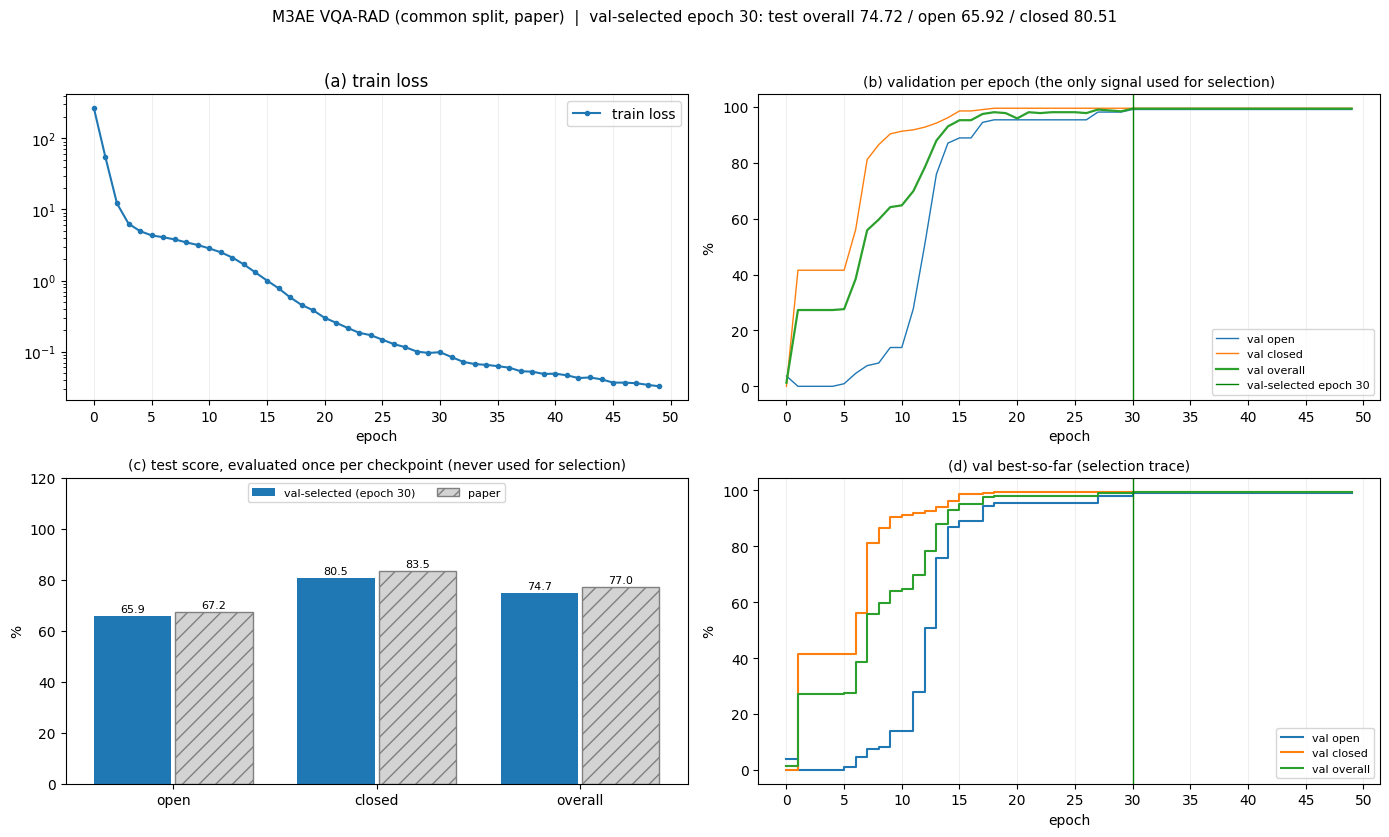

In [19]:
# 7-2. 학습 곡선 (TensorBoard 로그에서 읽는다) — VQA-RAD 와 SLAKE. 선택 = val. 태그 이름은 레포 버전에 따라 다를 수 있어 먼저 목록을 출력하고, 맞는 태그를 못 찾으면 그 목록만 보여 준다.
import glob, re, os, sys
sys.path.insert(0, '/content')
import importlib, curve_plot; importlib.reload(curve_plot)      # 저장 셀로 갱신한 최신 코드를 쓰도록 다시 불러온다
from curve_plot import plot_curves
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

_test_rows = {r[0]: r[1] for r in rows}     # 7 절 결과표의 test 점수 (val 로 고른 best 체크포인트)

def m3ae_curves(ds, exp, title, out_png):
    # 학습 로그만 쓴다: test 단독 실행(exp 이름 + '_test')의 이벤트 폴더는 제외
    evs = sorted((p for p in glob.glob(f'/content/M3AE/result/{exp}*/**/events.out.tfevents.*', recursive=True) if f'{exp}_test' not in p), key=os.path.getmtime)
    assert evs, f'TensorBoard 이벤트 파일이 없습니다: /content/M3AE/result/{exp}*'
    acc = EventAccumulator(os.path.dirname(evs[-1]), size_guidance={'scalars': 0}); acc.Reload()
    tags = acc.Tags()['scalars']
    print(f'[{ds}] 태그:', tags)
    def series(pattern):
        t = next((x for x in tags if re.search(pattern, x)), None)
        return ({e.step: e.value for e in acc.Scalars(t)} if t else {}), t
    (vo, t1), (vco, t2), (vop, t3) = series(r'val/score_epoch$'), series(r'val/close.*score.*epoch$'), series(r'val/open.*score.*epoch$')
    (loss, t4) = series(r'train/.*loss.*epoch$|train/loss.*epoch$')
    print(f'[{ds}] 사용 태그:', dict(val_overall=t1, val_closed=t2, val_open=t3, train_loss=t4))
    assert vo, f'[{ds}] val overall 태그를 못 찾았습니다 — 위 태그 목록을 알려 주세요'
    idx = lambda d: {i: d[k] for i, k in enumerate(sorted(d))}      # step 이 global step 일 수 있어 값 순서로 epoch 를 다시 센다
    vo, vco, vop, loss = idx(vo), idx(vco), idx(vop), idx(loss)
    nan = float('nan')
    val = {e: {'overall': 100 * vo[e], 'closed': 100 * vco.get(e, nan), 'open': 100 * vop.get(e, nan)} for e in vo}
    sel = max(sorted(val), key=lambda e: (val[e]['overall'], -e))
    t = _test_rows.get(ds)
    test = {sel: {k: t[k] for k in ('open', 'closed', 'overall')}} if t else {}
    plot_curves(title, train_loss=loss, val=val, test=test, paper=paper[ds], out_png=out_png, selected=sel)
    print(f'[{ds}] 저장: {out_png}  (val epoch {len(val)}개, val-selected epoch {sel})')

for _ds, _exp, _title, _png in (('VQA-RAD', RAD_EXP, f'M3AE VQA-RAD ({RAD_SPLIT} split, {RAD_PROTOCOL})', f'{DRIVE_ROOT}/logs/{RAD_EXP}_curves.png'),
                                ('SLAKE', SLAKE_EXP, f'M3AE SLAKE (official split, {RAD_PROTOCOL})', f'{DRIVE_ROOT}/logs/{SLAKE_EXP}_curves.png')):
    try:
        m3ae_curves(_ds, _exp, _title, _png)
    except (AssertionError, OSError) as e:
        print(f'[{_ds}] 곡선 생략:', e)
